<a href="https://colab.research.google.com/github/bgeethagayathri2-del/MNIST-digit-recognition/blob/main/MNIST_digits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train shape: (60000, 28, 28) Test shape: (10000, 28, 28)


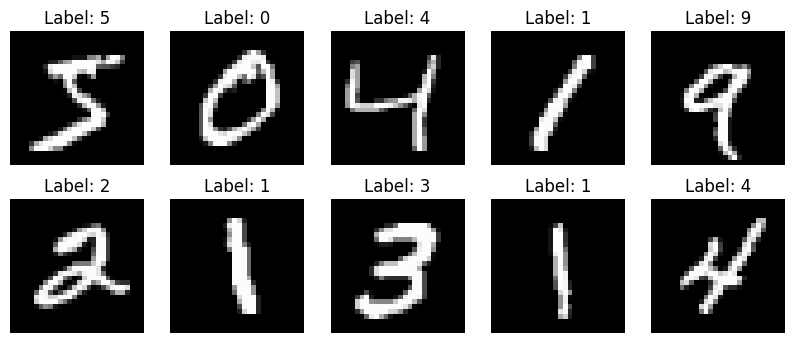

Epoch 1/5
1688/1688 - 11s - 6ms/step - accuracy: 0.9243 - loss: 0.2568 - val_accuracy: 0.9727 - val_loss: 0.0979
Epoch 2/5
1688/1688 - 9s - 6ms/step - accuracy: 0.9684 - loss: 0.1053 - val_accuracy: 0.9770 - val_loss: 0.0835
Epoch 3/5
1688/1688 - 12s - 7ms/step - accuracy: 0.9761 - loss: 0.0761 - val_accuracy: 0.9753 - val_loss: 0.0849
Epoch 4/5
1688/1688 - 7s - 4ms/step - accuracy: 0.9816 - loss: 0.0568 - val_accuracy: 0.9783 - val_loss: 0.0838
Epoch 5/5
1688/1688 - 8s - 5ms/step - accuracy: 0.9852 - loss: 0.0457 - val_accuracy: 0.9778 - val_loss: 0.0764
Simple NN test accuracy: 0.9774
Epoch 1/5
1688/1688 - 49s - 29ms/step - accuracy: 0.9446 - loss: 0.1890 - val_accuracy: 0.9835 - val_loss: 0.0552
Epoch 2/5
1688/1688 - 81s - 48ms/step - accuracy: 0.9786 - loss: 0.0689 - val_accuracy: 0.9863 - val_loss: 0.0474
Epoch 3/5
1688/1688 - 82s - 48ms/step - accuracy: 0.9832 - loss: 0.0523 - val_accuracy: 0.9905 - val_loss: 0.0346
Epoch 4/5
1688/1688 - 47s - 28ms/step - accuracy: 0.9869 - loss:

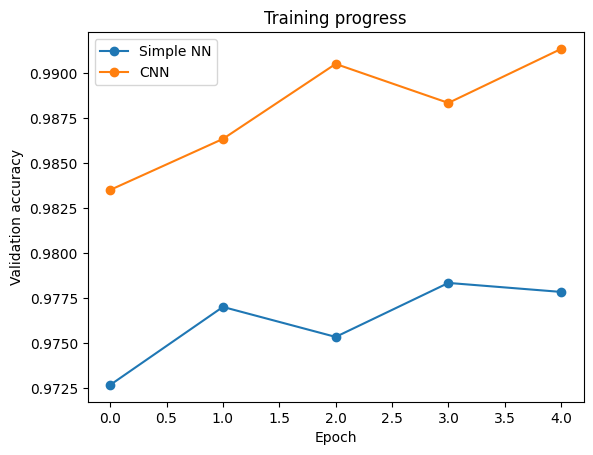

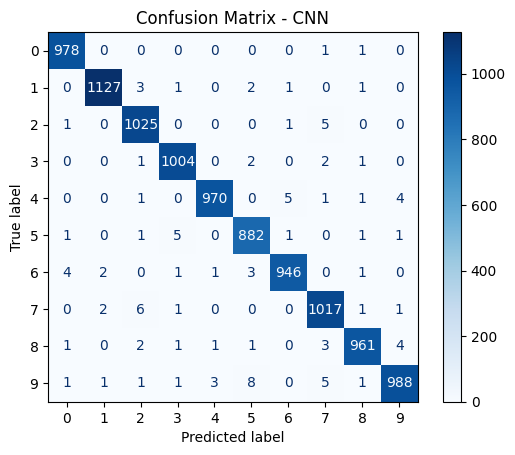

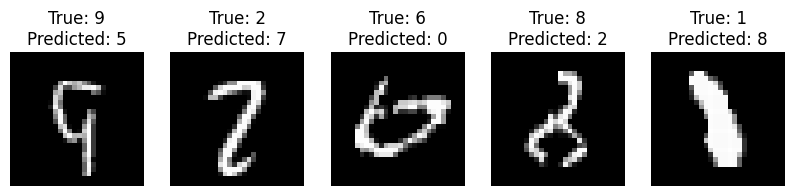

In [3]:
# MNIST Handwritten Digit Recognition: Neural Network vs CNN
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Load data (60,000 training images and 10,000 test images, each 28x28 pixels)
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# 2. Look at some samples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.show()

# 3. Scale pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

# 4. Model 1: simple neural network
nn = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
nn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_nn = nn.fit(X_train, y_train, epochs=5, validation_split=0.1, verbose=2)
nn_loss, nn_acc = nn.evaluate(X_test, y_test, verbose=0)
print("Simple NN test accuracy:", round(nn_acc, 4))

# 5. Model 2: CNN (looks at small patches of the image)
Xtr = X_train.reshape(-1, 28, 28, 1)
Xte = X_test.reshape(-1, 28, 28, 1)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_cnn = cnn.fit(Xtr, y_train, epochs=5, validation_split=0.1, verbose=2)
cnn_loss, cnn_acc = cnn.evaluate(Xte, y_test, verbose=0)
print("CNN test accuracy:", round(cnn_acc, 4))

# 6. Graph: accuracy while training
plt.plot(h_nn.history["val_accuracy"], marker="o", label="Simple NN")
plt.plot(h_cnn.history["val_accuracy"], marker="o", label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Training progress")
plt.legend()
plt.show()

# 7. Confusion matrix for the CNN
preds = cnn.predict(Xte, verbose=0).argmax(axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, preds)).plot(cmap="Blues")
plt.title("Confusion Matrix - CNN")
plt.show()

# 8. Look at some mistakes
wrong = np.where(preds != y_test)[0][:5]
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"True: {y_test[i]}\nPredicted: {preds[i]}")
    ax.axis("off")
plt.show()